# Notebook 2: นักสืบ — วัดระบบของครู แล้วหาจุดอ่อนพร้อมหลักฐาน (คู่กับ README บทที่ 7-9)

**ทำ notebook นี้เพื่ออะไร:** โจทย์ข้อ 2 ให้ปรับปรุงระบบของครู แต่จะปรับได้ตรงจุดก็ต่อเมื่อรู้ว่า **อ่อนตรงไหน และพิสูจน์ได้**
ถ้าเดาเอาเองแล้วแก้ อาจแก้ผิดที่ หรือแก้แล้วบอกครูไม่ได้ว่าดีขึ้นเพราะอะไร

**วิธีสืบที่ใช้ทั้ง notebook** (ใช้ได้กับทุกระบบ ไม่ใช่แค่ RAG):

```
อาการ (ตัวเลขผิดปกติ) → สมมติฐาน (น่าจะเพราะ...) → ทดลอง (print / นับ / _analyze) → ยืนยัน หรือ ตัดทิ้ง
```

**ต้องมีก่อนเริ่ม:** index ของระบบครู (ได้จากการรัน `authenticRAG.py` ตาม README บทที่ 7 ซึ่งเป็นการบ้านก่อนคาบนี้)

## 0. เตรียมสภาพแวดล้อม และตรวจว่ามี index ของครู

**ทำทำไม:** ทุกหัวข้อใน notebook นี้อ่านข้อมูลจาก index ที่โค้ดครูสร้าง ถ้าไม่มี จะพังทุก cell

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "steps"))

import statistics
import pandas as pd
pd.set_option("display.max_colwidth", None)
from common import notebook_setup
notebook_setup()                      # ปิดข้อความรก + เลือก font ไทยให้กราฟ
import matplotlib.pyplot as plt
from common import opensearch, read_corpus

client = opensearch()
VEC, BM25 = "anthropic-vector-index", "anthropic-bm25-index"
for name in (VEC, BM25):
    if not client.indices.exists(index=name):
        raise SystemExit(f"ไม่พบ {name}: รัน authenticRAG.py ของครูก่อน (README บทที่ 7)")
    print(f"{name}: {client.count(index=name)['count']} chunk")

anthropic-vector-index: 53 chunk
anthropic-bm25-index: 53 chunk


---
## 1. วัดระบบของครูก่อน (หาอาการ)

### คืออะไร
ใช้ชุดคำถาม 28 ข้อที่มีเฉลย (`steps/questions.json`) วัดว่าระบบครูหา chunk ที่มีคำตอบเจอไหม อยู่อันดับเท่าไร
แยกวัด 3 แบบ: BM25 อย่างเดียว, dense อย่างเดียว, hybrid (ระบบเต็มของครู)

**chunk ไหนนับว่า "ถูก":** chunk ที่มีข้อความ **evidence** (ข้อความที่คัดลอกตรงจากเอกสาร เป็นคำตอบของข้อนั้น) อยู่ข้างใน
ตัวอย่างข้อ q02:

In [2]:
import json
QUESTIONS = json.loads((ROOT / "steps" / "questions.json").read_text(encoding="utf-8"))
q02 = next(q for q in QUESTIONS if q["id"] == "q02")
print(json.dumps(q02, ensure_ascii=False, indent=1))
print("\nชนิดคำถาม:", pd.Series([q["type"] for q in QUESTIONS]).value_counts().to_dict())

{
 "id": "q02",
 "question": "ระยะฟักตัวของโรคหัดเยอรมันนานกี่วัน",
 "type": "specific",
 "file": "1.md",
 "evidence": [
  "ประมาณ 12-24 วัน",
  "โดยเฉลี่ยประมาณ 16-18 วัน"
 ],
 "reference_answer": "ระยะฟักตัวประมาณ 12-24 วัน โดยเฉลี่ยประมาณ 16-18 วัน"
}

ชนิดคำถาม: {'keyword': 8, 'specific': 8, 'paraphrase': 8, 'official': 5}


### ทำทำไม
- **วัดก่อนแก้:** ถ้าไม่มีตัวเลขของระบบเดิม ข้อ 3 ของโจทย์ ("ดีขึ้นอย่างไร") จะไม่มีอะไรเทียบ
- **แยก 3 แบบ:** ถ้าวัดแค่ hybrid จะไม่รู้ว่าขาไหนอ่อน (เหมือนหมอวัดแค่ "สุขภาพโดยรวม" ไม่ได้ตรวจทีละอวัยวะ)

ตัวชี้วัด:

| ตัวชี้วัด | ความหมาย |
|---|---|
| Hit@1 | สัดส่วนข้อที่อันดับ 1 เป็น chunk ถูก |
| Hit@5 | สัดส่วนข้อที่มี chunk ถูกใน 5 อันดับแรก (ระบบส่ง 5 chunk ให้ LLM) |
| MRR@5 | เฉลี่ย 1/อันดับ ของ chunk ถูกตัวแรก (อันดับ 1 = 1, อันดับ 2 = 0.5, ไม่เจอ = 0) |
| chars | ความยาวรวมของ 5 chunk ที่ส่งให้ LLM |

### ทำยังไง
1. โหลดชุดคำถาม 29 ข้อ (`steps/questions.json`) ใช้ 28 ข้อที่มี evidence
2. ใช้ `ev.SYSTEMS` ซึ่งเขียน query **เหมือนโค้ดครูทุกตัวอักษร** (ฝั่งละ 10, `best_fields`, RRF rank เริ่ม 0) เพื่อวัดระบบครูตามจริง ไม่ได้แอบแก้
3. `ev.evaluate()` วนทุกข้อ: ค้น → ดู 5 อันดับแรก → หาอันดับแรกที่ chunk มี evidence → คำนวณ Hit@1, Hit@5, MRR@5 และความยาวที่ส่งให้ LLM

### ทายก่อนรัน
BM25 ของครูจะหาเจอกี่ % ? (เครื่องมือค้นคำมาตรฐานของโลก ปกติควรได้ดีพอสมควร)

In [3]:
import step08_evaluate as ev        # ฟังก์ชันวัดผลกลาง (ใช้ query แบบเดียวกับโค้ดครูทุกตัวอักษร)

teacher = {name: ev.SYSTEMS[name] for name in ["ครู: BM25", "ครู: dense", "ครู: hybrid (ระบบเดิม)"]}
results, ranks = {}, {}
for name, run in teacher.items():
    results[name], ranks[name] = ev.evaluate(run)
pd.DataFrame(results).T.round(2)

,Hit@1,Hit@5,MRR@5,chars
ครู: BM25,0.00,0.07,0.04,1981.68
ครู: dense,0.68,0.96,0.78,10808.39
ครู: hybrid (ระบบเดิม),0.64,0.96,0.77,11100.32


### อ่านผล: อาการที่ต้องสืบ
- **อาการ 1:** BM25 Hit@5 = **0.07** = หาเจอ 2 จาก 28 ข้อ เครื่องมือค้นคำที่ใช้กันทั่วโลกไม่ควรแย่ขนาดนี้
- **อาการ 2:** hybrid Hit@1 **แย่กว่า** dense อย่างเดียว ทั้งที่สไลด์บอกว่า hybrid ต้องดีกว่า
- **อาการ 3:** Hit@5 สูงแต่ Hit@1 ต่ำกว่ามาก = chunk ถูกอยู่ใน 5 อันดับ แต่ไม่ค่อยเป็นอันดับ 1
- **อาการ 4:** ส่งให้ LLM เกิน 10,000 ตัวอักษรต่อคำถาม ทั้งที่คำตอบส่วนใหญ่ยาวแค่ 1-2 ประโยค

อาการ 2 อธิบายด้วยอาการ 1 ได้: ถ้าขา BM25 ส่งผลขยะมา RRF ก็เอาขยะมาปน → **เริ่มสืบที่ BM25**

---
## 2. จุดอ่อน 1: BM25 ใช้ analyzer `standard`

| ขั้น | |
|---|---|
| อาการ | BM25 หาเจอ 2 จาก 28 ข้อ |
| สมมติฐาน | term ในดัชนีกับ term ในคำถามไม่ตรงกัน (นึกถึง Notebook 1 หัวข้อ 3) |
| ทดลอง | ดู mapping ของ index จริง แล้วให้ OpenSearch ตัดข้อความด้วย analyzer **ของ field นั้นจริง ๆ** |

**คืออะไร:** `get_mapping` = ดู schema ที่ index ใช้อยู่จริง (ไม่ใช่ที่คิดว่าใช้), `analyze` แบบระบุ `index` + `field` = ตัดข้อความด้วย analyzer เดียวกับที่ field ใช้ตอนเก็บข้อมูล

**ทำทำไม:** ห้ามเชื่อว่าโค้ดเขียนอะไรแล้วระบบจะเป็นแบบนั้น ต้องดูของจริงที่อยู่ในระบบ

In [4]:
mapping = client.indices.get_mapping(index=BM25)[BM25]["mappings"]["properties"]
print("analyzer ของ field content:", mapping["content"].get("analyzer", "standard"))

docs = [h["_source"] for h in client.search(index=BM25, body={"size": 1000, "query": {"match_all": {}}})["hits"]["hits"]]
sample = docs[0]["content"][:80]
stored = [t["token"] for t in client.indices.analyze(index=BM25, body={"field": "content", "text": sample})["tokens"]]
print("\nข้อความในเอกสาร :", repr(sample))
print("term ที่เก็บในดัชนี:", stored)

q = "ระยะฟักตัวของโรคหัดเยอรมันนานกี่วัน"
q_terms = [t["token"] for t in client.indices.analyze(index=BM25, body={"field": "content", "text": q})["tokens"]]
print("\nคำถาม            :", q)
print("term ของคำถาม     :", q_terms)
hits = client.search(index=BM25, body={"query": {"multi_match": {"query": q, "fields": ["content", "contextualized_content"]}}})["hits"]["hits"]
print("BM25 ของครูค้นเจอ :", len(hits), "chunk")

analyzer ของ field content: standard

ข้อความในเอกสาร : '# หัดเยอรมัน อาการ สาเหตุ และการรักษาโรคหัดเยอรมัน 10 วิธี !!\n\nโดย เมดไทย, เมื่อ'
term ที่เก็บในดัชนี: ['หัดเยอรมัน', 'อาการ', 'สาเหตุ', 'และการรักษาโรคหัดเยอรมัน', '10', 'วิธี', 'โดย', 'เมดไทย', 'เมื่อ']

คำถาม            : ระยะฟักตัวของโรคหัดเยอรมันนานกี่วัน
term ของคำถาม     : ['ระยะฟักตัวของโรคหัดเยอรมันนานกี่วัน']
BM25 ของครูค้นเจอ : 0 chunk


### ยืนยัน
- term ในดัชนีคือ **วลีระหว่างช่องว่าง** เช่น `'และการรักษาโรคหัดเยอรมัน'` (ไม่ใช่คำ)
- คำถามทั้งประโยคก็กลายเป็น **term เดียว** `'ระยะฟักตัวของโรคหัดเยอรมันนานกี่วัน'` ซึ่งไม่มีทางตรงกับ term ไหนในดัชนี
- ผล: ค้นเจอ **0 chunk** ทั้งที่เอกสารมีคำตอบอยู่จริง

**สรุปจุดอ่อน 1:** `"analyzer": "standard"` ทำให้ขา BM25 ใช้กับภาษาไทยไม่ได้ → "hybrid" ของครูจริง ๆ คือ dense อย่างเดียว + ขยะ (อธิบายอาการ 1 และ 2)
ดูสไลด์หน้า 24 อีกครั้ง: term ในตัวอย่างของครูคือ `"และวิธีการรักษา"` ซึ่งเป็นวลี ปัญหานี้อยู่ในสไลด์มาตั้งแต่แรก

---
## 3. จุดอ่อน 2: Contextual Retrieval ไม่ได้ส่งเอกสารให้ LLM

| ขั้น | |
|---|---|
| อาการ | ดู context ที่ LLM สร้างให้แต่ละ chunk |
| สมมติฐาน | ? (ดูผลก่อนแล้วตั้งสมมติฐาน) |

**คืออะไร:** Contextual Retrieval (สไลด์หน้า 20, แนวคิดของ Anthropic) = ให้ LLM **อ่านเอกสารทั้งฉบับ** แล้วเขียนบริบทสั้น ๆ ว่า chunk นี้อยู่ตรงไหนของเอกสาร
เช่น "ส่วนนี้ของบทความโรคหัดเยอรมัน กล่าวถึงระยะฟักตัว" แล้วเอาไปแปะกับ chunk ก่อน embed และทำ BM25

**ทำทำไม (ทำไมต้องสืบตรงนี้):** context คือสิ่งที่ทำให้ระบบนี้ชื่อ "Authentic RAG" ถ้ามันไม่ทำงาน ระบบก็เป็นแค่ RAG ธรรมดา

In [5]:
ctx = pd.DataFrame([{"chunk (ต้น)": d["content"][:45].replace("\n", " "), "context ที่ LLM สร้าง": d["contextualized_content"][:120]} for d in docs[:6]])
display(ctx)

is_english = lambda s: sum(c.isascii() and c.isalpha() for c in s) > 0.5 * max(len(s), 1)
n_en = sum(is_english(d["contextualized_content"]) for d in docs)
print(f"context ที่เป็นภาษาอังกฤษ: {n_en} จาก {len(docs)}")

,chunk (ต้น),context ที่ LLM สร้าง
0,# หัดเยอรมัน อาการ สาเหตุ และการรักษาโรคหัดเย,"Title and publication information for an article about German Measles symptoms, causes, and treatments."
1,"## โรคหัดเยอรมัน หัดเยอรมัน, เหือด หรือ หัดส","Overview of German measles (Rubella), including its definition, symptoms, risks to pregnant women, prevalence, and etymo"
2,## สาเหตุของโรคหัดเยอรมัน สาเหตุ : เกิดจากเช,"This chunk provides detailed information regarding the causes, transmission methods, pathogenesis, incubation period, an"
3,## อาการของโรคหัดเยอรมัน อาการของโรคหัดเยอรม,"This chunk provides a detailed description of the symptoms of rubella, covering the prodromal phase, the rash phase in c"
4,## ภาวะแทรกซ้อนของโรคหัดเยอรมัน โดยทั่วไปภาว,Complications of Rubella
5,### ภาวะแทรกซ้อนที่อาจพบได้ในคนทั่วไปที่เป็นโ,Complications of Rubella in the general population.


context ที่เป็นภาษาอังกฤษ: 53 จาก 53


### อ่านผล และตั้งสมมติฐาน
- context เกือบทั้งหมดเป็น **ภาษาอังกฤษ** (prompt ของครูเป็นภาษาอังกฤษ) ผู้ใช้ถามภาษาไทย BM25 จึงไม่มีทาง match กับ context (BM25 ข้ามภาษาไม่ได้ Notebook 1 หัวข้อ 5)
- เนื้อหาของ context อ่านเหมือน **"สรุปหัวข้อของ chunk ตัวเอง"** ไม่ได้บอกว่าอยู่ตรงไหนของเอกสาร
- **สมมติฐาน:** LLM ไม่ได้เห็นเอกสารเต็มตามที่ prompt ตั้งใจ

### ทดลอง: ดูว่าโค้ดครูส่งอะไรเป็น `<document>`
โค้ดครู (`authenticRAG.py` ฟังก์ชัน `add_documents_with_context`):

```python
full_doc_content = doc.page_content  # ถ้าไม่มีเอกสารเต็ม ใช้ chunk เอง
context = self.generate_context(full_doc_content, doc.page_content)
```

ลองจำลองด้วยข้อมูลจริง: เอา chunk หนึ่งมาสร้าง prompt แบบเดียวกับโค้ดครู

In [6]:
chunk = docs[2]["content"]
full_doc_content = chunk                    # แบบที่โค้ดครูทำจริง (doc.page_content คือ chunk)
prompt = f"""<document>
{full_doc_content}
</document>

Here is the chunk we want to situate within the whole document:
<chunk>
{chunk}
</chunk>"""
print("ความยาว <document>:", len(full_doc_content), "ตัวอักษร")
print("ความยาว <chunk>   :", len(chunk), "ตัวอักษร")
print("ทั้งไฟล์ 1.md จริง ๆ ยาว:", len(read_corpus()["1.md"]), "ตัวอักษร")
print("<document> == <chunk> ?", full_doc_content == chunk)

ความยาว <document>: 2256 ตัวอักษร
ความยาว <chunk>   : 2256 ตัวอักษร
ทั้งไฟล์ 1.md จริง ๆ ยาว: 23967 ตัวอักษร
<document> == <chunk> ? True


### ยืนยัน
`<document>` กับ `<chunk>` คือ **ข้อความเดียวกัน** LLM ไม่เคยเห็นเอกสารเต็ม (ซึ่งยาวกว่าหลายสิบเท่า) จึงทำได้แค่สรุป chunk ตัวเองซ้ำ

**บทเรียนของนักสืบ:** ชื่อตัวแปรบอกว่า `full_doc_content` (เอกสารเต็ม) แต่ค่าจริงคือ chunk
comment ก็บอกเองว่า "ถ้าไม่มีเอกสารเต็ม ใช้ chunk เอง" แต่ในโค้ดไม่เคยมีการส่งเอกสารเต็มเข้ามาเลย
→ **อย่าเชื่อชื่อตัวแปร ให้ print ค่าจริง**

**สรุปจุดอ่อน 2:** Contextual Retrieval ไม่ได้ทำงานตามหลักการ (สไลด์หน้า 20) และ context เป็นภาษาอังกฤษ ไม่ช่วย BM25 ภาษาไทย

---
## 4. จุดอ่อน 3: `chunk_size=256` ไม่มีผล

| ขั้น | |
|---|---|
| อาการ | (ยังไม่รู้) ลองดูขนาดของ chunk |
| สมมติฐาน | โค้ดครูตั้ง `MarkdownNodeParser(chunk_size=256)` chunk น่าจะยาวไม่เกิน ~256 |

**คืออะไร:** chunk คือท่อนข้อความที่ตัดจากเอกสาร ขนาดของ chunk มีผลกับทุกอย่างหลังจากนั้น (embedding, การค้น, สิ่งที่ส่งให้ LLM)

**ทำทำไม:** Notebook 1 หัวข้อ 2 เห็นแล้วว่า embedding ของข้อความยาวหลายเรื่องจะ "เบลอ" ถ้า chunk ใหญ่เกินจะค้นไม่แม่น

53 chunk  min=112  median=1188  max=8404  ตัวอักษร
chunk ที่ยาวเกิน 1,500 ตัวอักษร: 22


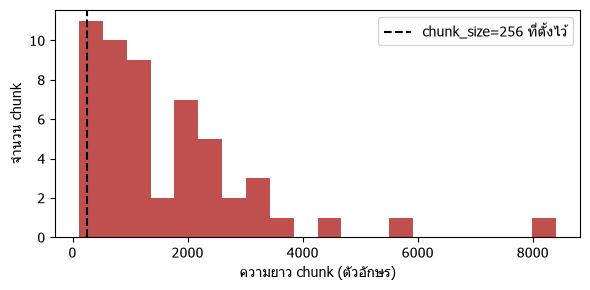

In [7]:
sizes = sorted(len(d["content"]) for d in docs)
print(f"{len(docs)} chunk  min={sizes[0]}  median={statistics.median(sizes):.0f}  max={sizes[-1]}  ตัวอักษร")
print("chunk ที่ยาวเกิน 1,500 ตัวอักษร:", sum(s > 1500 for s in sizes))

plt.figure(figsize=(6, 3))
plt.hist(sizes, bins=20, color="#c0504d")
plt.axvline(256, ls="--", color="k", label="chunk_size=256 ที่ตั้งไว้")
plt.xlabel("ความยาว chunk (ตัวอักษร)"); plt.ylabel("จำนวน chunk"); plt.legend(); plt.tight_layout(); plt.show()

### อ่านผล
chunk ยาวตั้งแต่ ~100 ถึง **8,404 ตัวอักษร** ส่วนใหญ่ยาวกว่า 256 มาก สมมติฐานผิด → ตั้งสมมติฐานใหม่: **`MarkdownNodeParser` ไม่ได้ใช้ค่า `chunk_size`**

### ทดลอง: รันตัวตัดของครูด้วย chunk_size ต่างกันมาก ๆ
ถ้า `chunk_size` มีผล จำนวน chunk ต้องต่างกัน

In [8]:
from llama_index.core import Document
from llama_index.core.node_parser import MarkdownNodeParser

text = read_corpus()["1.md"]
for size in [64, 256, 4096]:
    nodes = MarkdownNodeParser(chunk_size=size).get_nodes_from_documents([Document(text=text)])
    lens = [len(n.text) for n in nodes]
    print(f"chunk_size={size:5}  ->  {len(nodes)} chunk, ยาวสุด {max(lens):,} ตัวอักษร")

chunk_size=   64  ->  17 chunk, ยาวสุด 3,156 ตัวอักษร
chunk_size=  256  ->  17 chunk, ยาวสุด 3,156 ตัวอักษร
chunk_size= 4096  ->  17 chunk, ยาวสุด 3,156 ตัวอักษร


### ยืนยัน
ใส่ `chunk_size` 64, 256 หรือ 4096 ได้ผล **เหมือนกันทุกประการ** → `MarkdownNodeParser` ตัดตามหัวข้อ markdown อย่างเดียว ค่านี้ไม่มีผล

**ผลกระทบ:** chunk ใหญ่ทำให้ (1) embedding เบลอ (2) reranker (Notebook 3) อ่านได้ไม่ครบ (3) ส่งให้ LLM ยาวเกิน 10,000 ตัวอักษร (อาการ 4)

---
## 5. จุดอ่อน 4: ประมาณจำนวน token ด้วยการนับช่องว่าง

โค้ดครู (`truncate_context`):

```python
words = context.split()                 # ตัดที่ช่องว่าง
estimated_tokens = len(words) * 1.3
```

**คืออะไร:** ก่อนส่ง context ให้ LLM โค้ดครูจะตัดให้ไม่เกิน 4,000 token กัน prompt ยาวเกิน โดยประมาณ token จากจำนวนคำ
**ทำทำไม (ต้องสนใจ):** ถ้านับ token ผิด เกราะกันที่ตั้งใจไว้ (ไม่ส่งเกิน 4,000 token) จะไม่ทำงานจริง context อาจยาวเกินที่ LLM รับได้ หรือเปลืองเงินโดยไม่รู้ตัว
**ทำยังไง:** เอาทั้งไฟล์ `1.md` มาใส่สูตรของครู เทียบจำนวนที่สูตรประเมินกับจำนวนตัวอักษรจริง และดูว่าจะถูกตัดไหม

**สมมติฐาน (จากหลัก "สงสัยสมมติฐานภาษาอังกฤษ"):** `split()` ตัดที่ช่องว่าง ภาษาไทยไม่มีช่องว่างระหว่างคำ จะนับผิดมาก

In [9]:
t = read_corpus()["1.md"]
print(f"ไฟล์ 1.md ยาว {len(t):,} ตัวอักษร")
print(f"สูตรของครูประเมินว่า {len(t.split()) * 1.3:,.0f} token")
print(f"เพดานของ truncate_context = 4,000 token  ->  ถูกตัดไหม? {len(t.split()) * 1.3 > 4000}")

ไฟล์ 1.md ยาว 23,967 ตัวอักษร
สูตรของครูประเมินว่า 1,729 token
เพดานของ truncate_context = 4,000 token  ->  ถูกตัดไหม? False


### ยืนยัน
ทั้งไฟล์ยาวเกือบ 24,000 ตัวอักษร (ของจริงหลายหมื่น token) แต่สูตรประเมินได้แค่ไม่ถึง 2,000 → `truncate_context` **แทบไม่เคยตัด** แม้ส่งทั้งไฟล์
(จุดนี้ระบบใหม่ไม่ต้องแก้ตรง ๆ เพราะเมื่อ chunk เล็กลง context ที่ส่งก็เล็กลงเอง)

---
## 6. จุดอ่อน 5: RRF ที่ rank เริ่ม 0 และดึง candidate น้อย

โค้ดครู:

```python
for rank, (doc_id, score, source) in enumerate(results):      # enumerate เริ่มที่ 0
    fused_scores[doc_id] += 1.0 / (k + rank)
```

**คืออะไร:** สูตร RRF มาตรฐานคือ 1/(k + rank) โดย rank เริ่มที่ **1** และโค้ดครูดึงฝั่งละแค่ 10 อันดับ
**ทำยังไง:** คำนวณคะแนนอันดับแรกทั้งสองแบบ (rank = 0 กับ rank = 1) และดูจากผลวัดหัวข้อ 1 ว่ามีข้อไหนที่ dense ของครูหาไม่เจอใน 5 อันดับ (ข้อที่ candidate กว้างกว่านี้อาจช่วยได้)

**ทำทำไม (ต้องสนใจ):** ผลต่างเล็ก แต่เวลาอธิบายสูตรในรายงาน สูตรกับโค้ดต้องตรงกัน และ candidate น้อยทำให้ chunk ถูกที่อยู่อันดับลึกไม่มีโอกาส

In [10]:
print("อันดับแรกตามโค้ดครู (rank=0):", round(1 / (60 + 0), 5))
print("อันดับแรกตามสูตร   (rank=1):", round(1 / (60 + 1), 5))
deep = [(qid, r) for qid, r in ranks["ครู: dense"].items() if r is None]
print("\nข้อที่ dense ของครูไม่เจอใน 5 อันดับ:", deep or "ไม่มี")

อันดับแรกตามโค้ดครู (rank=0): 0.01667
อันดับแรกตามสูตร   (rank=1): 0.01639

ข้อที่ dense ของครูไม่เจอใน 5 อันดับ: [('q09', None)]


### อ่านผล
- คะแนนต่างกันแค่ ~0.0003 ต่ออันดับ แทบไม่ทำให้อันดับเปลี่ยน → จุดอ่อนนี้เป็นเรื่อง **ความถูกต้องของสูตร** (ต้องตรงกับที่เขียนในรายงาน) มากกว่าผลลัพธ์
- ข้อที่ dense ของครูหาไม่เจอใน 5 อันดับคือ q09 (คำถามแบบภาษาชาวบ้าน "โรคห่า") ถ้าดึง candidate กว้างขึ้นแล้วให้ reranker คัด จะมีโอกาสเจอ (Notebook 3: ระบบใหม่เจอข้อนี้ที่อันดับ 3)

---
## 7. จุดอ่อน 6: ไม่มี reranking (และ prompt หลวม)

| ขั้น | |
|---|---|
| อาการ | อาการ 3: Hit@5 สูงแต่ Hit@1 ต่ำ |
| สมมติฐาน | การค้นแบบเร็ว (bi-encoder) หาเจอ แต่จัดอันดับไม่แม่น |
**คืออะไร:** reranker คือขั้นที่เอา chunk ที่ค้นมาได้ (เช่น 20 อัน) มา **อ่านคู่กับคำถามทีละคู่** แล้วจัดอันดับใหม่ ต่างจากการค้นแบบ embedding ที่แปลงคำถามกับ chunk แยกกัน
**ทำทำไม:** อาการ 3 (Hit@5 สูงแต่ Hit@1 ต่ำ) บอกว่าระบบ "หาเจอ แต่เรียงไม่ถูก" ถ้าเป็นแบบนั้นจริง การเพิ่มขั้นเรียงใหม่จะคุ้มกว่าการไปแก้การค้น
**ทำยังไง:** นับว่าในระบบเต็มของครู chunk ที่มีคำตอบตกอยู่อันดับไหนบ้างกี่ข้อ ถ้ามีหลายข้ออยู่อันดับ 2-5 = สมมติฐานถูก

| ทดลอง | ดูอันดับรายข้อ |

In [11]:
r = pd.Series(ranks["ครู: hybrid (ระบบเดิม)"]).fillna("ไม่เจอ")
print("อันดับของ chunk ถูก (ระบบเต็มของครู) นับจำนวนข้อ:")
print(r.value_counts().sort_index(key=lambda s: s.map(lambda x: 99 if x == "ไม่เจอ" else x)).to_string())

อันดับของ chunk ถูก (ระบบเต็มของครู) นับจำนวนข้อ:
1.0       18
2.0        5
3.0        2
4.0        1
5.0        1
ไม่เจอ     1


### อ่านผล
มีหลายข้อที่ chunk ถูกอยู่อันดับ 2-5 ไม่ใช่ 1 → ถ้าระบบมีขั้นที่ "อ่านคำถามกับ chunk คู่กันแล้วจัดอันดับใหม่" (reranker) น่าจะดันขึ้นได้
สไลด์หน้า 19 ของ Anthropic แสดงว่า reranking ลด failed retrieval จาก 2.9% เหลือ 1.9% แต่โค้ดครูไม่มีขั้นนี้

**prompt ตอบคำถามของครู** บอกแค่ `Answer the question as truthful and helpful as possible` ไม่สั่งให้ตอบจาก context เท่านั้น ไม่ให้อ้างอิง
→ คำถามที่ไม่มีคำตอบในเอกสาร **เสี่ยง** ให้ LLM แต่ง (ขึ้นกับว่าโมเดลจะระวังเองไหม)

---
## สรุป: แฟ้มคดี 6 จุดอ่อน

| # | จุดอ่อน | หลักฐานใน notebook นี้ | กระทบอะไร | แก้ใน Notebook 3 |
|---|---|---|---|---|
| 1 | analyzer `standard` | term เป็นวลี, ค้นเจอ 0, BM25 Hit@5 = 0.07 | ขา BM25 ใช้ไม่ได้ hybrid แย่กว่า dense | P3 |
| 2 | context ไม่เห็นเอกสาร | `<document> == <chunk>`, context เป็นอังกฤษเกือบหมด | Contextual Retrieval ไม่ทำงาน | P2 |
| 3 | `chunk_size` ไม่มีผล | ใส่ 64/256/4096 ได้ผลเท่ากัน, chunk ยาวถึง 8,404 | embedding เบลอ, context ยาว | P1 |
| 4 | นับ token ด้วยช่องว่าง | 24,000 ตัวอักษร ประเมินได้ < 2,000 token | ไม่เคยตัด context | P1 (chunk เล็กลงเอง) |
| 5 | RRF rank เริ่ม 0, candidate น้อย | สูตรต่างจากมาตรฐาน | พลาด chunk อันดับลึก | P5 |
| 6 | ไม่มี rerank, prompt หลวม | Hit@1 ต่ำกว่า Hit@5 มาก | อันดับ 1 ไม่แม่น, เสี่ยงแต่ง | P6, P7 |

**การบ้านก่อน Notebook 3:** เขียนทางแก้ของแต่ละจุดเองอย่างน้อย 2 ทาง แล้วเลือกทางที่คิดว่าดีที่สุดพร้อมเหตุผล
แล้วค่อยเทียบกับที่ Notebook 3 เลือก (ถ้าเลือกต่างและมีเหตุผล ไม่ผิด ลองทำแล้ววัดเลย)